# Phase 3 — AlexNet (2012)

GPU 시대의 시작. **ReLU + Max Pooling + Dropout**으로 깊은 CNN을 학습하고,
과적합을 억제하는 두 축(Dropout, Data Augmentation)을 직접 비교한다.

- 모델: `src/dl_history/models/alexnet.py` (Conv 5층 + MaxPool + FC 3층, 28×28 입력에 맞게 축소)
- 데이터 증강: `src/dl_history/data.py`의 `train_transform(augment=True)` (RandomCrop + Flip)
- 전체 실험 재현: `uv run python scripts/run_phase3.py`


In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import torch

from dl_history.data import load_fashion_mnist_loaders, train_transform
from dl_history.models.alexnet import AlexNet
from dl_history.train import train_model

torch.manual_seed(0)


## 1. 출력 크기 공식 검증 — `W_out = (W − F + 2P) / S + 1`

AlexNet 원본은 224×224 RGB 입력이지만, Fashion-MNIST(28×28 grayscale)에 맞게
stem과 classifier 폭을 줄였다. Conv/Pool을 거친 실제 텐서 크기가 손 계산과 일치하는지 확인한다.


In [2]:
model = AlexNet()

x = torch.randn(2, 1, 28, 28)
x = model.pool(model.act(model.conv1(x)))   # F=5,P=2 → 28; pool 3×3,s2,p1 → 14
x = model.pool(model.act(model.conv2(x)))   # F=5,P=2 → 14; pool → 7
x = model.act(model.conv3(x))               # F=3,P=1 → 7
x = model.act(model.conv4(x))               # F=3,P=1 → 7
x = model.pool(model.act(model.conv5(x)))   # F=3,P=1 → 7; pool → 4
print("pool3 output:", tuple(x.shape))
assert x.shape[1:] == (256, 4, 4)
assert x.numel() // 2 == model.fc6.in_features == 4096  # flatten dim


pool3 output: (2, 256, 4, 4)


## 2. 레이어별 파라미터 수

AlexNet 전체 파라미터는 **약 770만 개** — LeNet-5(6.1만)의 100배 이상이다.
무거운 부분은 classifier(fc6/fc7)이며, Phase 3 실험의 과적합도 여기서 나온다.


In [3]:
rows = [(name, tuple(p.shape), p.numel()) for name, p in model.named_parameters()]
for name, shape, n in rows:
    print(f"{name:14s} {str(shape):16s} {n:>9,}")
print(f"{'total':14s} {'':16s} {sum(n for *_, n in rows):>9,}")


conv1.weight   (64, 1, 5, 5)        1,600
conv1.bias     (64,)                   64
conv2.weight   (192, 64, 5, 5)    307,200
conv2.bias     (192,)                 192
conv3.weight   (384, 192, 3, 3)   663,552
conv3.bias     (384,)                 384
conv4.weight   (256, 384, 3, 3)   884,736
conv4.bias     (256,)                 256
conv5.weight   (256, 256, 3, 3)   589,824
conv5.bias     (256,)                 256
fc6.weight     (1024, 4096)     4,194,304
fc6.bias       (1024,)              1,024
fc7.weight     (1024, 1024)     1,048,576
fc7.bias       (1024,)              1,024
fc8.weight     (10, 1024)          10,240
fc8.bias       (10,)                   10
total                           7,703,242


## 3. Dropout — inverted dropout 스케일링 확인

PyTorch `nn.Dropout`은 **inverted dropout**을 쓴다.

- 학습 시: 각 유닛을 확률 `1−p`로 유지하고, 살아남은 값을 `1/(1−p)`로 **스케일 업**
- 평가 시: 아무것도 하지 않음(identity)

덕분에 기대값이 학습/평가에서 동일해져, 테스트 시 별도 rescaling이 필요 없다.
아래에서 직접 확인한다.


In [4]:
drop = AlexNet(dropout=0.5)
captured = {}
handle = drop.dropout.register_forward_hook(
    lambda m, i, o: captured.update(inp=i[0].detach(), out=o.detach())
)
drop.train()
with torch.no_grad():
    drop(torch.randn(128, 1, 28, 28))
handle.remove()

inp, out = captured["inp"], captured["out"]
alive = inp != 0                                   # ReLU가 이미 음수를 0으로
kept = out[alive]
zero_frac = (kept == 0).float().mean().item()
survivors = alive & (out != 0)
scaled = (out[survivors] / inp[survivors]).mean().item()
print(f"train mode: zeroed {zero_frac:.3f} of live units (p=0.5), survivors ×{scaled:.2f}")

drop.eval()
x = torch.randn(4, 1, 28, 28)
with torch.no_grad():
    assert torch.equal(drop(x), drop(x))            # eval mode → deterministic (identity)
print("eval mode: dropout is identity (deterministic)")


train mode: zeroed 0.499 of live units (p=0.5), survivors ×2.00
eval mode: dropout is identity (deterministic)


## 4. Exp A — Dropout 전/후 과적합 비교

동일한 AlexNet에서 `dropout=0.0`과 `dropout=0.5`를 학습시킨다.
Dropout이 없으면 train accuracy는 빠르게 1.0에 도달하지만 validation은 정체되고,
**train − val gap**이 벌어진다. (노트북 데모는 3 epoch, 전체 실험은 스크립트에서 15 epoch)


In [5]:
EPOCHS = 3
loaders = load_fashion_mnist_loaders(batch_size=128)

histories = {}
for dropout in [0.0, 0.5]:
    torch.manual_seed(0)
    model = AlexNet(dropout=dropout)
    history, sec = train_model(model, loaders, epochs=EPOCHS, lr=0.01, momentum=0.9)
    histories[f"dropout={dropout}"] = history
    gap = history.train_acc[-1] - history.val_acc[-1]
    print(f"dropout={dropout}: train/val acc = {history.train_acc[-1]:.4f}/{history.val_acc[-1]:.4f} "
          f"(gap {gap:+.4f})  ({sec:.1f}s/epoch)")


dropout=0.0: train/val acc = 0.8784/0.8733 (gap +0.0051)  (11.7s/epoch)


dropout=0.5: train/val acc = 0.8719/0.8862 (gap -0.0143)  (11.7s/epoch)


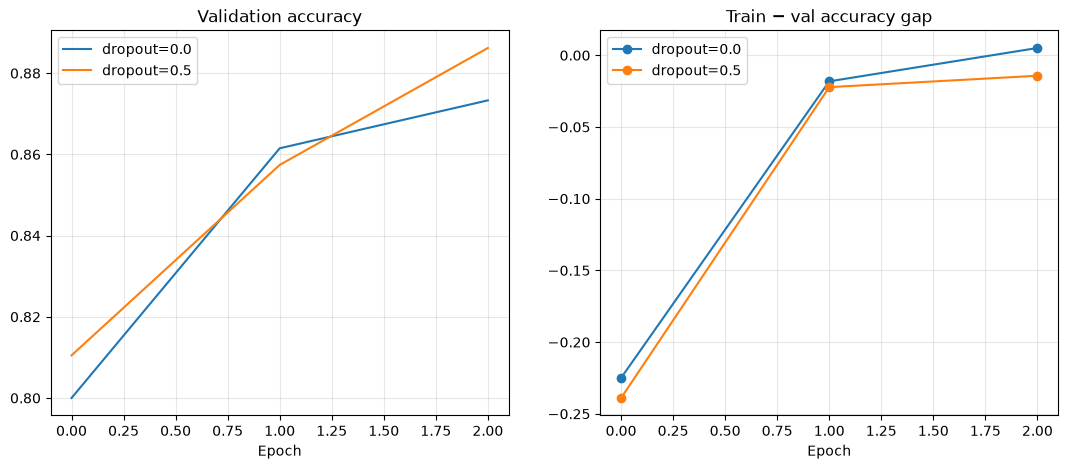

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for label, hist in histories.items():
    axes[0].plot(hist.val_acc, label=label)
    axes[1].plot([t - v for t, v in zip(hist.train_acc, hist.val_acc)], marker="o", label=label)
axes[0].set_title("Validation accuracy"); axes[0].set_xlabel("Epoch")
axes[1].set_title("Train − val accuracy gap"); axes[1].set_xlabel("Epoch")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.show()


## 5. Exp B — Data Augmentation (RandomCrop + Flip)

Dropout과 별개로, 입력에 무작위 이동/반전을 주면 모델이 위치·방향에 덜 의존하게 되어
일반화가 좋아진다. `augment=False` vs `augment=True` 로더를 비교한다.


augment=False: final val acc = 0.8862  (11.7s/epoch)


augment=True: final val acc = 0.8387  (12.3s/epoch)


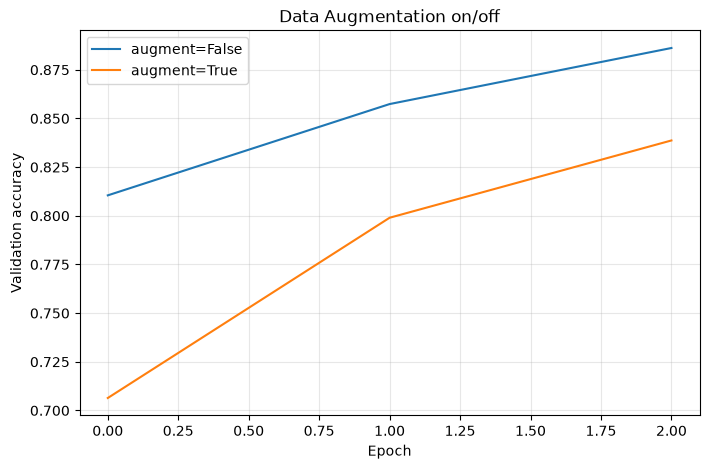

In [7]:
aug_histories = {}
for augment in [False, True]:
    torch.manual_seed(0)
    loader = load_fashion_mnist_loaders(batch_size=128, augment=augment)
    history, sec = train_model(AlexNet(dropout=0.5), loader, epochs=EPOCHS, lr=0.01, momentum=0.9)
    aug_histories[f"augment={augment}"] = history
    print(f"augment={augment}: final val acc = {history.val_acc[-1]:.4f}  ({sec:.1f}s/epoch)")

fig, ax = plt.subplots(figsize=(8, 5))
for label, hist in aug_histories.items():
    ax.plot(hist.val_acc, label=label)
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation accuracy")
ax.set_title("Data Augmentation on/off"); ax.grid(alpha=0.3); ax.legend()
plt.show()


## 정리

- AlexNet은 ReLU + MaxPool로 깊은 CNN을 학습하고, 770만 파라미터의 classifier가
  과적합의 주 원인이다.
- **Dropout**은 train−val gap을 줄여 일반화를 돕는다 (inverted dropout이라 테스트 시
  rescaling이 필요 없다).
- **Data Augmentation**은 입력 다양성을 늘려 검증 정확도를 추가로 끌어올린다.
- 다음 Phase 4(VGG)에서는 3×3 커널 중첩과 BatchNorm으로 더 깊은 망의 학습 안정성을 다룬다.
